In [50]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

In [51]:
# 나눔고딕으로 폰트 변경
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'NanumGothic'

In [52]:
# matplot의 폰트와 폰트 크기 확인
print(plt.rcParams['font.family'], plt.rcParams['font.size'])

['NanumGothic'] 10.0


In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [54]:
default_data = pd.read_csv('모델 kappa(디폴트_fi_pca_pi).csv')
paper_data = pd.read_csv('모델 kappa(논문 기준_fi_pca_pi).csv')
gs_data = pd.read_csv('모델 kappa(그리드서치_fi_pca_pi).csv')

In [55]:
default_data.head()

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트),default_kappa(pi_교차검증),default_kappa(pi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065,0.974217,0.971326
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424,0.977491,0.979520
2,SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519,0.963983,0.970506
3,DecisionTreeClassifier,0.921622,0.927913,0.922438,0.927097,0.836481,0.836986,0.932468,0.926275


In [56]:
paper_data.head()

,모델,논문_kappa(교차검증),논문_kappa(테스트),논문_kappa(fi_교차검증),논문_kappa(fi_테스트),논문_kappa(pca_교차검증),논문_kappa(pca_테스트),논문_kappa(pi_교차검증),논문_kappa(pi_테스트)
0,RandomForest,0.944539,0.943468,0.944748,0.975423,0.870207,0.854815,0.940859,0.927100
1,LogisticRegression,0.980355,0.977061,0.975443,0.974602,0.978514,0.977878,0.980969,0.983615
2,SVM,0.981992,0.981156,0.975239,0.977878,0.982606,0.981157,0.981172,0.971325
3,DecisionTreeClassifier,0.871177,0.858261,0.870770,0.858261,0.736754,0.719897,0.876502,0.858261


In [57]:
gs_data.head()

,모델,gs_kappa(교차검증),gs_kappa(테스트),gs_kappa(fi_교차검증),gs_kappa(fi_테스트),gs_kappa(pca_교차검증),gs_kappa(pca_테스트),gs_kappa(pi_교차검증),gs_kappa(pi_테스트)
0,RandomForest,0.964190,0.959855,0.964803,0.961492,0.907074,0.897540,0.947402,0.942626
1,LogisticRegression,0.980970,0.978700,0.974420,0.978698,0.980970,0.979518,0.981788,0.977060
2,SVM,0.986085,0.987711,0.985266,0.987712,0.986289,0.992626,0.977490,0.977881
3,DecisionTreeClassifier,0.930012,0.930363,0.930625,0.939381,0.846930,0.859080,0.940454,0.938548


In [58]:
df = default_data.merge(paper_data, left_on=['모델'], right_on=['모델'])
df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트),default_kappa(pi_교차검증),default_kappa(pi_테스트),논문_kappa(교차검증),논문_kappa(테스트),논문_kappa(fi_교차검증),논문_kappa(fi_테스트),논문_kappa(pca_교차검증),논문_kappa(pca_테스트),논문_kappa(pi_교차검증),논문_kappa(pi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065,0.974217,0.971326,0.944539,0.943468,0.944748,0.975423,0.870207,0.854815,0.940859,0.927100
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424,0.977491,0.979520,0.980355,0.977061,0.975443,0.974602,0.978514,0.977878,0.980969,0.983615
2,SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519,0.963983,0.970506,0.981992,0.981156,0.975239,0.977878,0.982606,0.981157,0.981172,0.971325
3,DecisionTreeClassifier,0.921622,0.927913,0.922438,0.927097,0.836481,0.836986,0.932468,0.926275,0.871177,0.858261,0.870770,0.858261,0.736754,0.719897,0.876502,0.858261


In [59]:
df = df.merge(gs_data, left_on=['모델'], right_on=['모델'])
df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트),default_kappa(pi_교차검증),default_kappa(pi_테스트),논문_kappa(교차검증),...,논문_kappa(pi_교차검증),논문_kappa(pi_테스트),gs_kappa(교차검증),gs_kappa(테스트),gs_kappa(fi_교차검증),gs_kappa(fi_테스트),gs_kappa(pca_교차검증),gs_kappa(pca_테스트),gs_kappa(pi_교차검증),gs_kappa(pi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065,0.974217,0.971326,0.944539,...,0.940859,0.927100,0.964190,0.959855,0.964803,0.961492,0.907074,0.897540,0.947402,0.942626
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424,0.977491,0.979520,0.980355,...,0.980969,0.983615,0.980970,0.978700,0.974420,0.978698,0.980970,0.979518,0.981788,0.977060
2,SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519,0.963983,0.970506,0.981992,...,0.981172,0.971325,0.986085,0.987711,0.985266,0.987712,0.986289,0.992626,0.977490,0.977881
3,DecisionTreeClassifier,0.921622,0.927913,0.922438,0.927097,0.836481,0.836986,0.932468,0.926275,0.871177,...,0.876502,0.858261,0.930012,0.930363,0.930625,0.939381,0.846930,0.859080,0.940454,0.938548


In [60]:
df.to_csv('기본 모델링 kappa(종합).csv', index=False, encoding='utf-8-sig')

In [61]:
df

,모델,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트),default_kappa(pi_교차검증),default_kappa(pi_테스트),논문_kappa(교차검증),...,논문_kappa(pi_교차검증),논문_kappa(pi_테스트),gs_kappa(교차검증),gs_kappa(테스트),gs_kappa(fi_교차검증),gs_kappa(fi_테스트),gs_kappa(pca_교차검증),gs_kappa(pca_테스트),gs_kappa(pi_교차검증),gs_kappa(pi_테스트)
0,RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065,0.974217,0.971326,0.944539,...,0.940859,0.927100,0.964190,0.959855,0.964803,0.961492,0.907074,0.897540,0.947402,0.942626
1,LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424,0.977491,0.979520,0.980355,...,0.980969,0.983615,0.980970,0.978700,0.974420,0.978698,0.980970,0.979518,0.981788,0.977060
2,SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519,0.963983,0.970506,0.981992,...,0.981172,0.971325,0.986085,0.987711,0.985266,0.987712,0.986289,0.992626,0.977490,0.977881
3,DecisionTreeClassifier,0.921622,0.927913,0.922438,0.927097,0.836481,0.836986,0.932468,0.926275,0.871177,...,0.876502,0.858261,0.930012,0.930363,0.930625,0.939381,0.846930,0.859080,0.940454,0.938548


In [62]:
df.set_index('모델', inplace=True)

In [63]:
df

,default_kappa(교차검증),default_kappa(테스트),default_kappa(fi_교차검증),default_kappa(fi_테스트),default_kappa(pca_교차검증),default_kappa(pca_테스트),default_kappa(pi_교차검증),default_kappa(pi_테스트),논문_kappa(교차검증),논문_kappa(테스트),...,논문_kappa(pi_교차검증),논문_kappa(pi_테스트),gs_kappa(교차검증),gs_kappa(테스트),gs_kappa(fi_교차검증),gs_kappa(fi_테스트),gs_kappa(pca_교차검증),gs_kappa(pca_테스트),gs_kappa(pi_교차검증),gs_kappa(pi_테스트)
모델,,,,,,,,,,,,,,,,,,,,,
RandomForest,0.972580,0.973782,0.975446,0.973785,0.934302,0.936065,0.974217,0.971326,0.944539,0.943468,...,0.940859,0.927100,0.964190,0.959855,0.964803,0.961492,0.907074,0.897540,0.947402,0.942626
LogisticRegression,0.979946,0.977063,0.971761,0.976242,0.980150,0.975424,0.977491,0.979520,0.980355,0.977061,...,0.980969,0.983615,0.980970,0.978700,0.974420,0.978698,0.980970,0.979518,0.981788,0.977060
SVM,0.961731,0.968043,0.962549,0.964772,0.974626,0.979519,0.963983,0.970506,0.981992,0.981156,...,0.981172,0.971325,0.986085,0.987711,0.985266,0.987712,0.986289,0.992626,0.977490,0.977881
DecisionTreeClassifier,0.921622,0.927913,0.922438,0.927097,0.836481,0.836986,0.932468,0.926275,0.871177,0.858261,...,0.876502,0.858261,0.930012,0.930363,0.930625,0.939381,0.846930,0.859080,0.940454,0.938548


In [64]:
df_cv = df[[
    'default_kappa(교차검증)', 'default_kappa(fi_교차검증)', 'default_kappa(pca_교차검증)', 'default_kappa(pi_교차검증)',
    '논문_kappa(교차검증)', '논문_kappa(fi_교차검증)', '논문_kappa(pca_교차검증)', '논문_kappa(pi_교차검증)',
    'gs_kappa(교차검증)', 'gs_kappa(fi_교차검증)', 'gs_kappa(pca_교차검증)', 'gs_kappa(pi_교차검증)'
]]

In [65]:
df_test = df[[
    'default_kappa(테스트)', 'default_kappa(fi_테스트)', 'default_kappa(pca_테스트)', 'default_kappa(pi_테스트)',
    '논문_kappa(테스트)', '논문_kappa(fi_테스트)', '논문_kappa(pca_테스트)', '논문_kappa(pi_테스트)',
    'gs_kappa(테스트)', 'gs_kappa(fi_테스트)', 'gs_kappa(pca_테스트)', 'gs_kappa(pi_테스트)'
]]

In [66]:
# 교차검증 데이터프레임
# 최대값 계산
max_value = df_cv.values.max()

# 최대값의 위치 찾기
max_positions = df_cv.stack()[df_cv.stack() == max_value]

# (행 이름, 열 이름) 쌍 출력
print("최대값:", max_value)
print("최대값의 위치 (행, 열):")
for row, col in max_positions.index:
    print(f"({row}, {col})")

최대값: 0.9862890704991916
최대값의 위치 (행, 열):
(SVM, gs_kappa(pca_교차검증))


In [67]:
# 테스트 데이터프레임
# 최대값 계산
max_value = df_test.values.max()

# 최대값의 위치 찾기
max_positions = df_test.stack()[df_test.stack() == max_value]

# (행 이름, 열 이름) 쌍 출력
print("최대값:", max_value)
print("최대값의 위치 (행, 열):")
for row, col in max_positions.index:
    print(f"({row}, {col})")

최대값: 0.992626258406784
최대값의 위치 (행, 열):
(SVM, gs_kappa(pca_테스트))


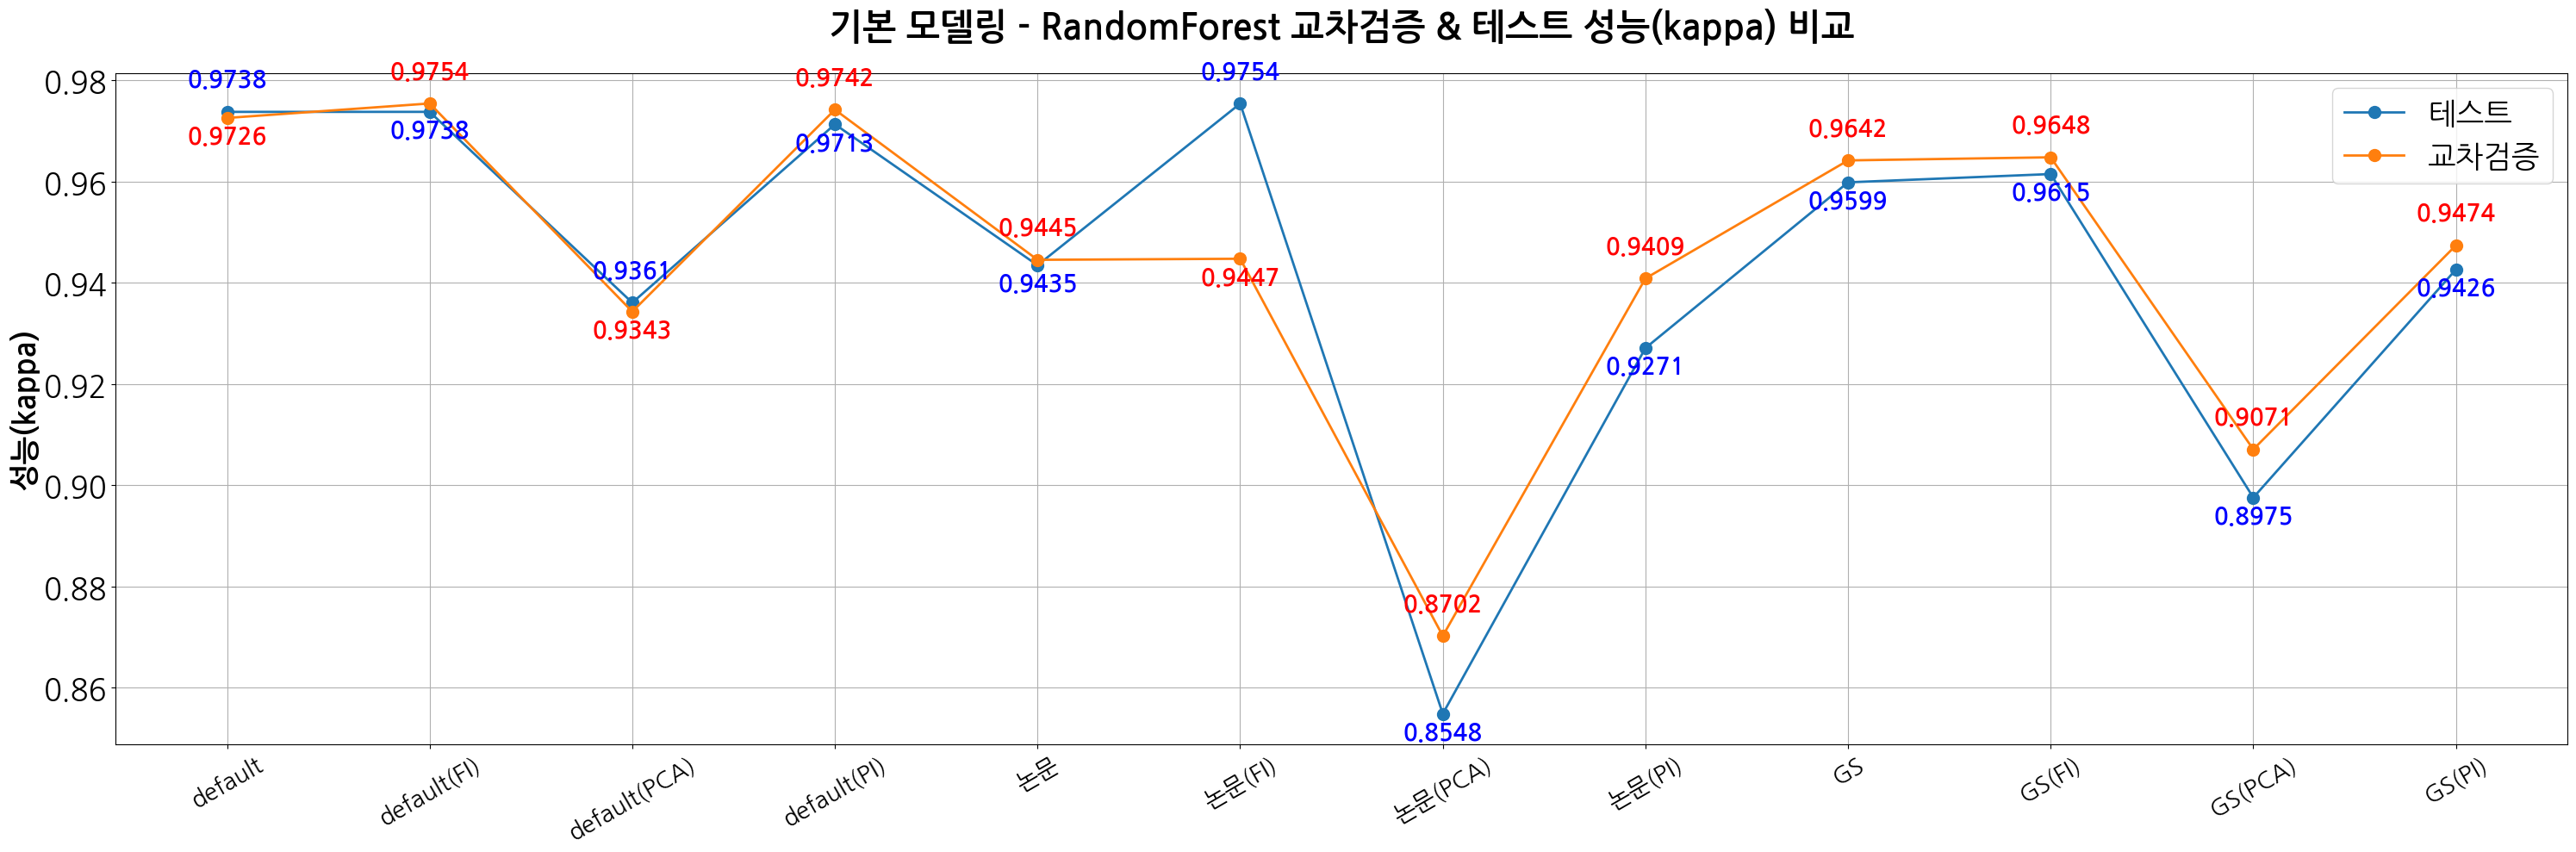

In [68]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']

# RandomForest 테스트 및 교차검증 정확도 추출
rf_test = df.loc['RandomForest', [
    'default_kappa(테스트)', 'default_kappa(fi_테스트)', 'default_kappa(pca_테스트)', 'default_kappa(pi_테스트)',
    '논문_kappa(테스트)', '논문_kappa(fi_테스트)', '논문_kappa(pca_테스트)', '논문_kappa(pi_테스트)',
    'gs_kappa(테스트)', 'gs_kappa(fi_테스트)', 'gs_kappa(pca_테스트)', 'gs_kappa(pi_테스트)'
]]

rf_cv = df.loc['RandomForest', [
    'default_kappa(교차검증)', 'default_kappa(fi_교차검증)', 'default_kappa(pca_교차검증)', 'default_kappa(pi_교차검증)',
    '논문_kappa(교차검증)', '논문_kappa(fi_교차검증)', '논문_kappa(pca_교차검증)', '논문_kappa(pi_교차검증)',
    'gs_kappa(교차검증)', 'gs_kappa(fi_교차검증)', 'gs_kappa(pca_교차검증)', 'gs_kappa(pi_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, rf_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, rf_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

# 각 지점에서 더 큰 값은 위, 더 작은 값은 아래에 표시
for i, (test_val, cv_val) in enumerate(zip(rf_test.values, rf_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.005, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.005, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.005, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.005, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')


# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(kappa)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - RandomForest 교차검증 & 테스트 성능(kappa) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

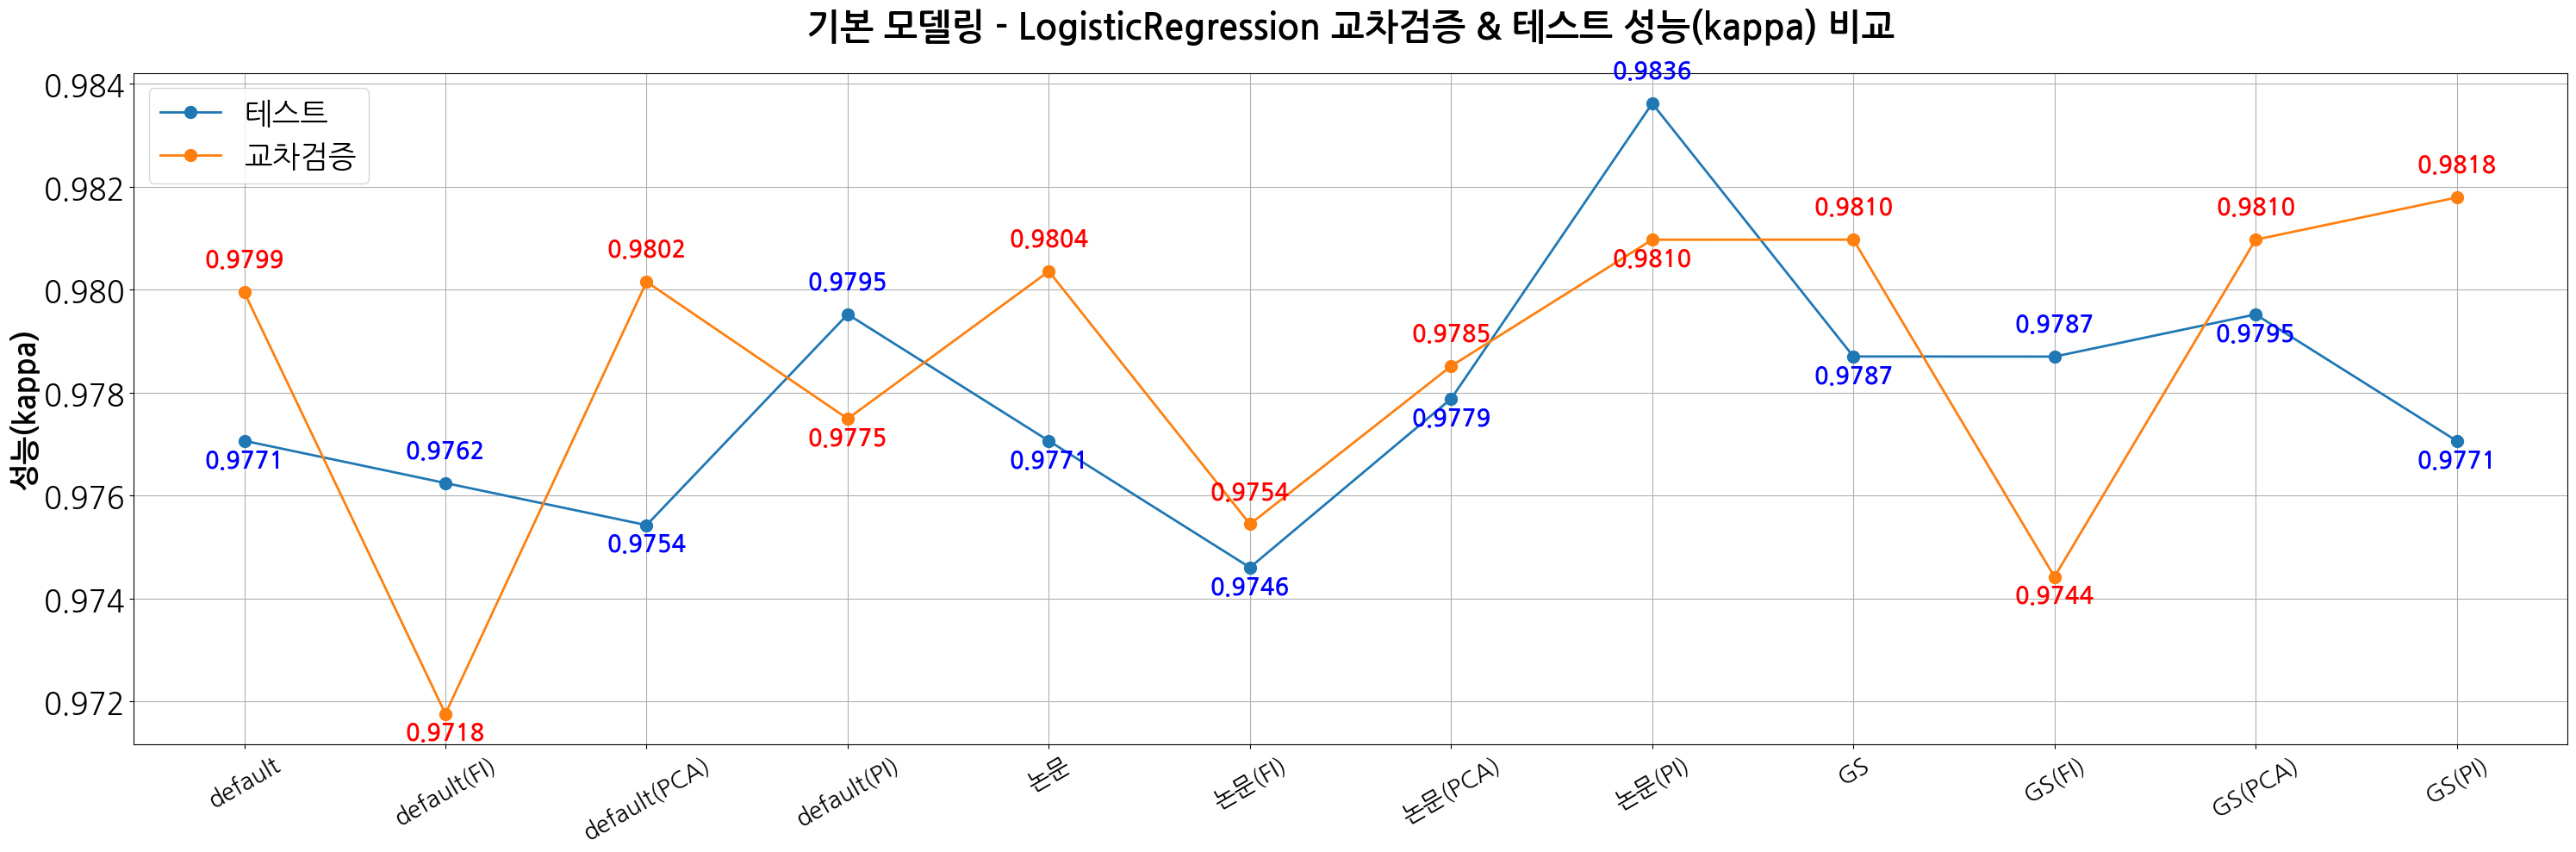

In [69]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']

# LogisticRegression 테스트 및 교차검증 정확도 추출
lr_test = df.loc['LogisticRegression', [
    'default_kappa(테스트)', 'default_kappa(fi_테스트)', 'default_kappa(pca_테스트)', 'default_kappa(pi_테스트)',
    '논문_kappa(테스트)', '논문_kappa(fi_테스트)', '논문_kappa(pca_테스트)', '논문_kappa(pi_테스트)',
    'gs_kappa(테스트)', 'gs_kappa(fi_테스트)', 'gs_kappa(pca_테스트)', 'gs_kappa(pi_테스트)'
]]

lr_cv = df.loc['LogisticRegression', [
    'default_kappa(교차검증)', 'default_kappa(fi_교차검증)', 'default_kappa(pca_교차검증)', 'default_kappa(pi_교차검증)',
    '논문_kappa(교차검증)', '논문_kappa(fi_교차검증)', '논문_kappa(pca_교차검증)', '논문_kappa(pi_교차검증)',
    'gs_kappa(교차검증)', 'gs_kappa(fi_교차검증)', 'gs_kappa(pca_교차검증)', 'gs_kappa(pi_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, lr_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, lr_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

# 각 지점에서 더 큰 값은 위, 더 작은 값은 아래에 표시
for i, (test_val, cv_val) in enumerate(zip(lr_test.values, lr_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.0005, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.0005, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.0005, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.0005, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')


# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(kappa)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - LogisticRegression 교차검증 & 테스트 성능(kappa) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

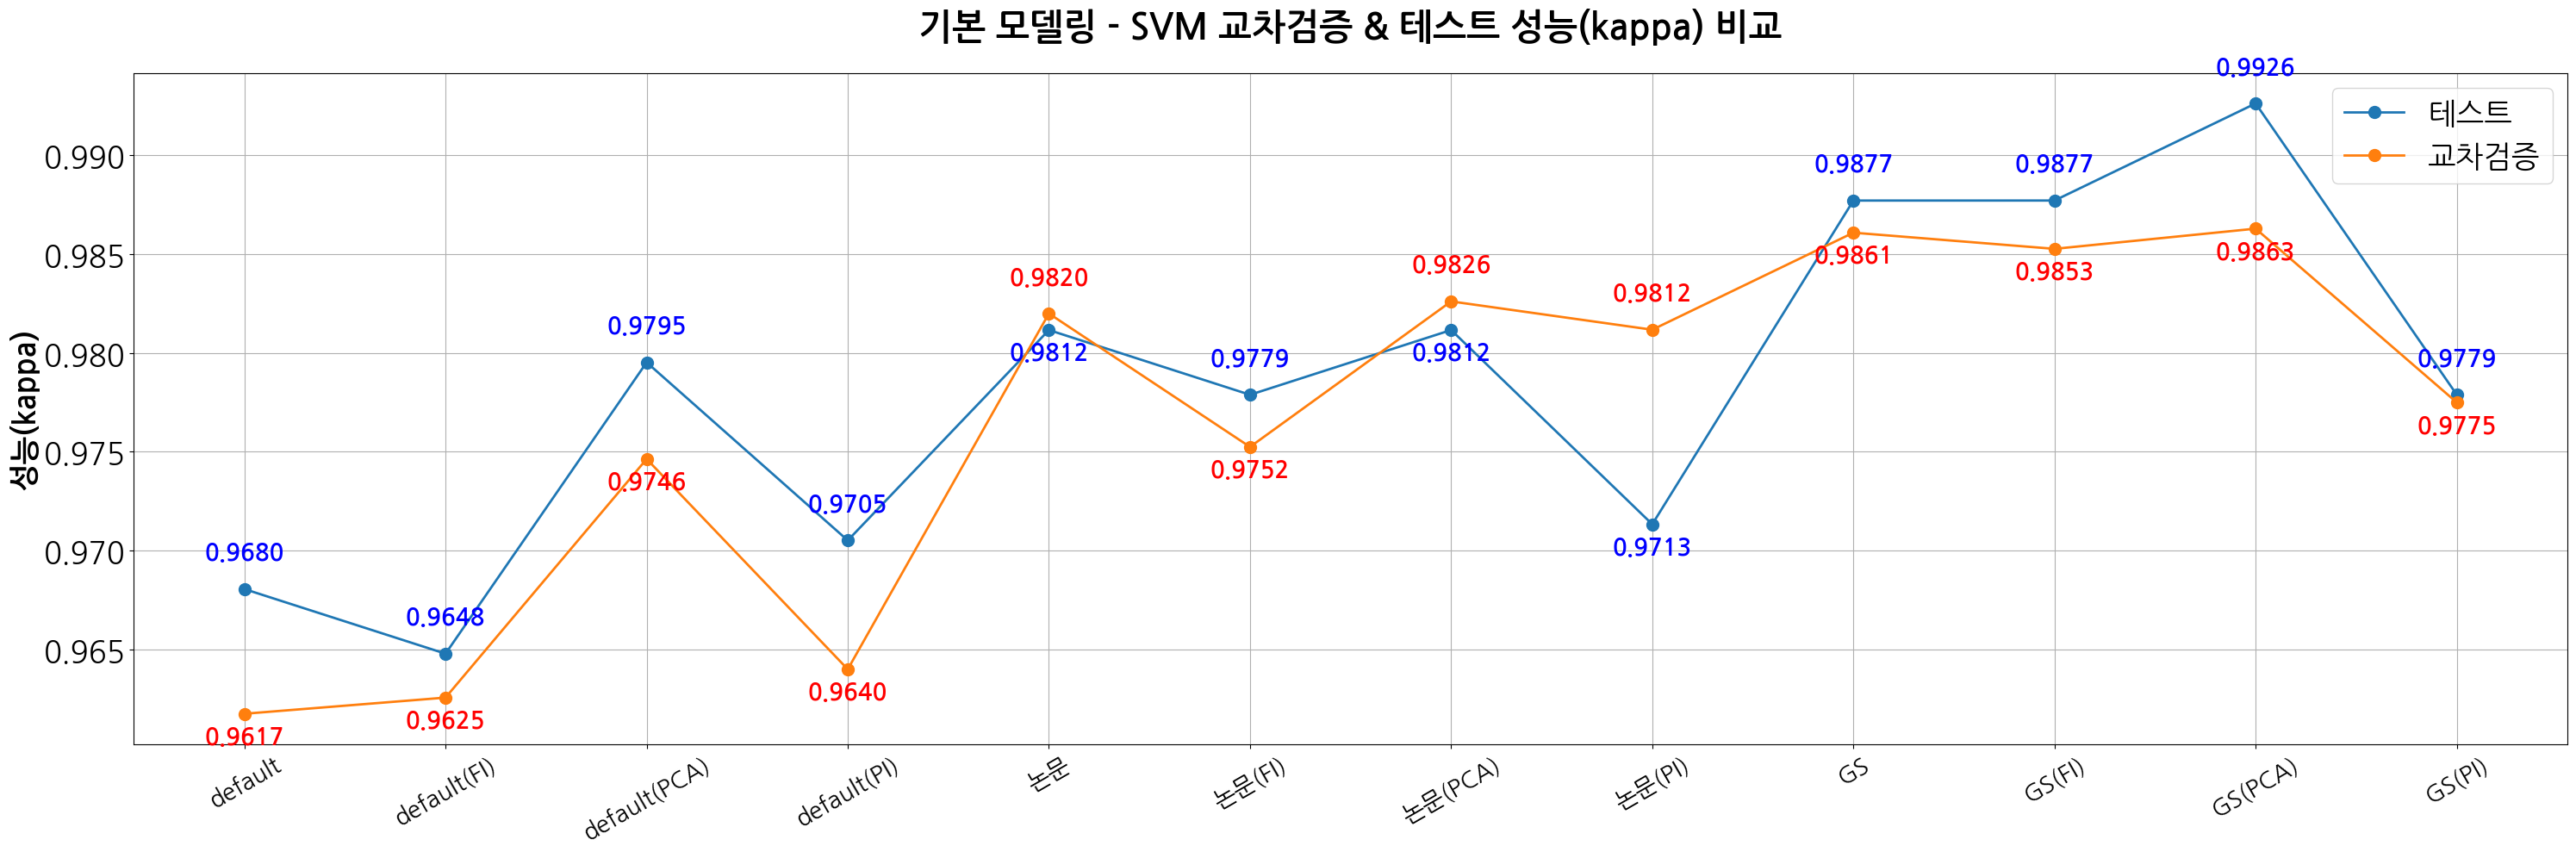

In [70]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']

# SVM 테스트 및 교차검증 정확도 추출
svm_test = df.loc['SVM', [
    'default_kappa(테스트)', 'default_kappa(fi_테스트)', 'default_kappa(pca_테스트)', 'default_kappa(pi_테스트)',
    '논문_kappa(테스트)', '논문_kappa(fi_테스트)', '논문_kappa(pca_테스트)', '논문_kappa(pi_테스트)',
    'gs_kappa(테스트)', 'gs_kappa(fi_테스트)', 'gs_kappa(pca_테스트)', 'gs_kappa(pi_테스트)'
]]

svm_cv = df.loc['SVM', [
    'default_kappa(교차검증)', 'default_kappa(fi_교차검증)', 'default_kappa(pca_교차검증)', 'default_kappa(pi_교차검증)',
    '논문_kappa(교차검증)', '논문_kappa(fi_교차검증)', '논문_kappa(pca_교차검증)', '논문_kappa(pi_교차검증)',
    'gs_kappa(교차검증)', 'gs_kappa(fi_교차검증)', 'gs_kappa(pca_교차검증)', 'gs_kappa(pi_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, svm_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, svm_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

for i, (test_val, cv_val) in enumerate(zip(svm_test.values, svm_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.0015, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.0015, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.0015, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.0015, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(kappa)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - SVM 교차검증 & 테스트 성능(kappa) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

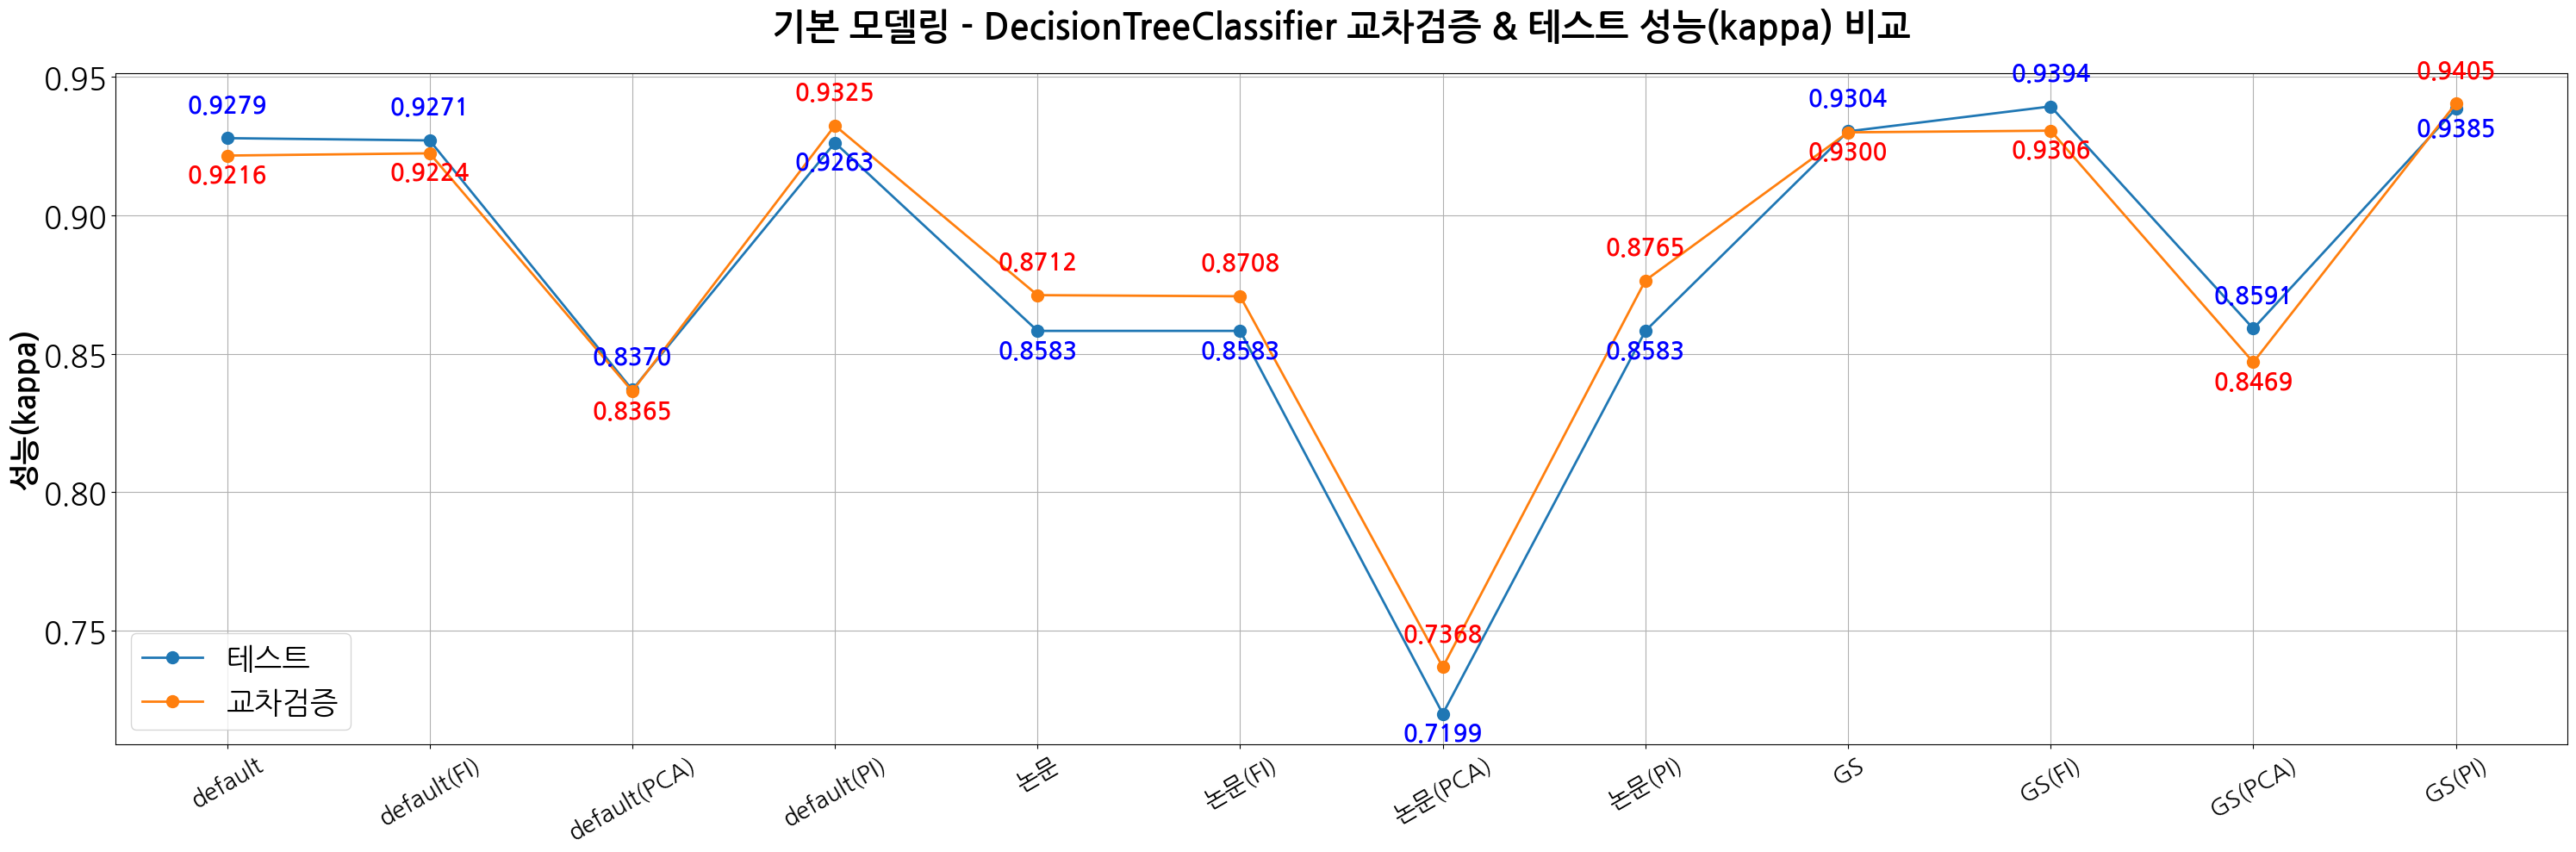

In [71]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']

# DecisionTreeClassifier 테스트 및 교차검증 정확도 추출
dt_test = df.loc['DecisionTreeClassifier', [
    'default_kappa(테스트)', 'default_kappa(fi_테스트)', 'default_kappa(pca_테스트)', 'default_kappa(pi_테스트)',
    '논문_kappa(테스트)', '논문_kappa(fi_테스트)', '논문_kappa(pca_테스트)', '논문_kappa(pi_테스트)',
    'gs_kappa(테스트)', 'gs_kappa(fi_테스트)', 'gs_kappa(pca_테스트)', 'gs_kappa(pi_테스트)'
]]

dt_cv = df.loc['DecisionTreeClassifier', [
    'default_kappa(교차검증)', 'default_kappa(fi_교차검증)', 'default_kappa(pca_교차검증)', 'default_kappa(pi_교차검증)',
    '논문_kappa(교차검증)', '논문_kappa(fi_교차검증)', '논문_kappa(pca_교차검증)', '논문_kappa(pi_교차검증)',
    'gs_kappa(교차검증)', 'gs_kappa(fi_교차검증)', 'gs_kappa(pca_교차검증)', 'gs_kappa(pi_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, dt_test.values, marker='o', markersize=10, linewidth=2, label='테스트')
plt.plot(x_labels, dt_cv.values, marker='o', markersize=10, linewidth=2, label='교차검증')

for i, (test_val, cv_val) in enumerate(zip(dt_test.values, dt_cv.values)):
    if test_val >= cv_val:
        plt.text(i, test_val + 0.0095, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val - 0.0095, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')
    else:
        plt.text(i, test_val - 0.0095, f"{test_val:.4f}", ha='center', fontsize=20, color='blue', fontweight='bold')
        plt.text(i, cv_val + 0.0095, f"{cv_val:.4f}", ha='center', fontsize=20, color='red', fontweight='bold')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(kappa)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - DecisionTreeClassifier 교차검증 & 테스트 성능(kappa) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

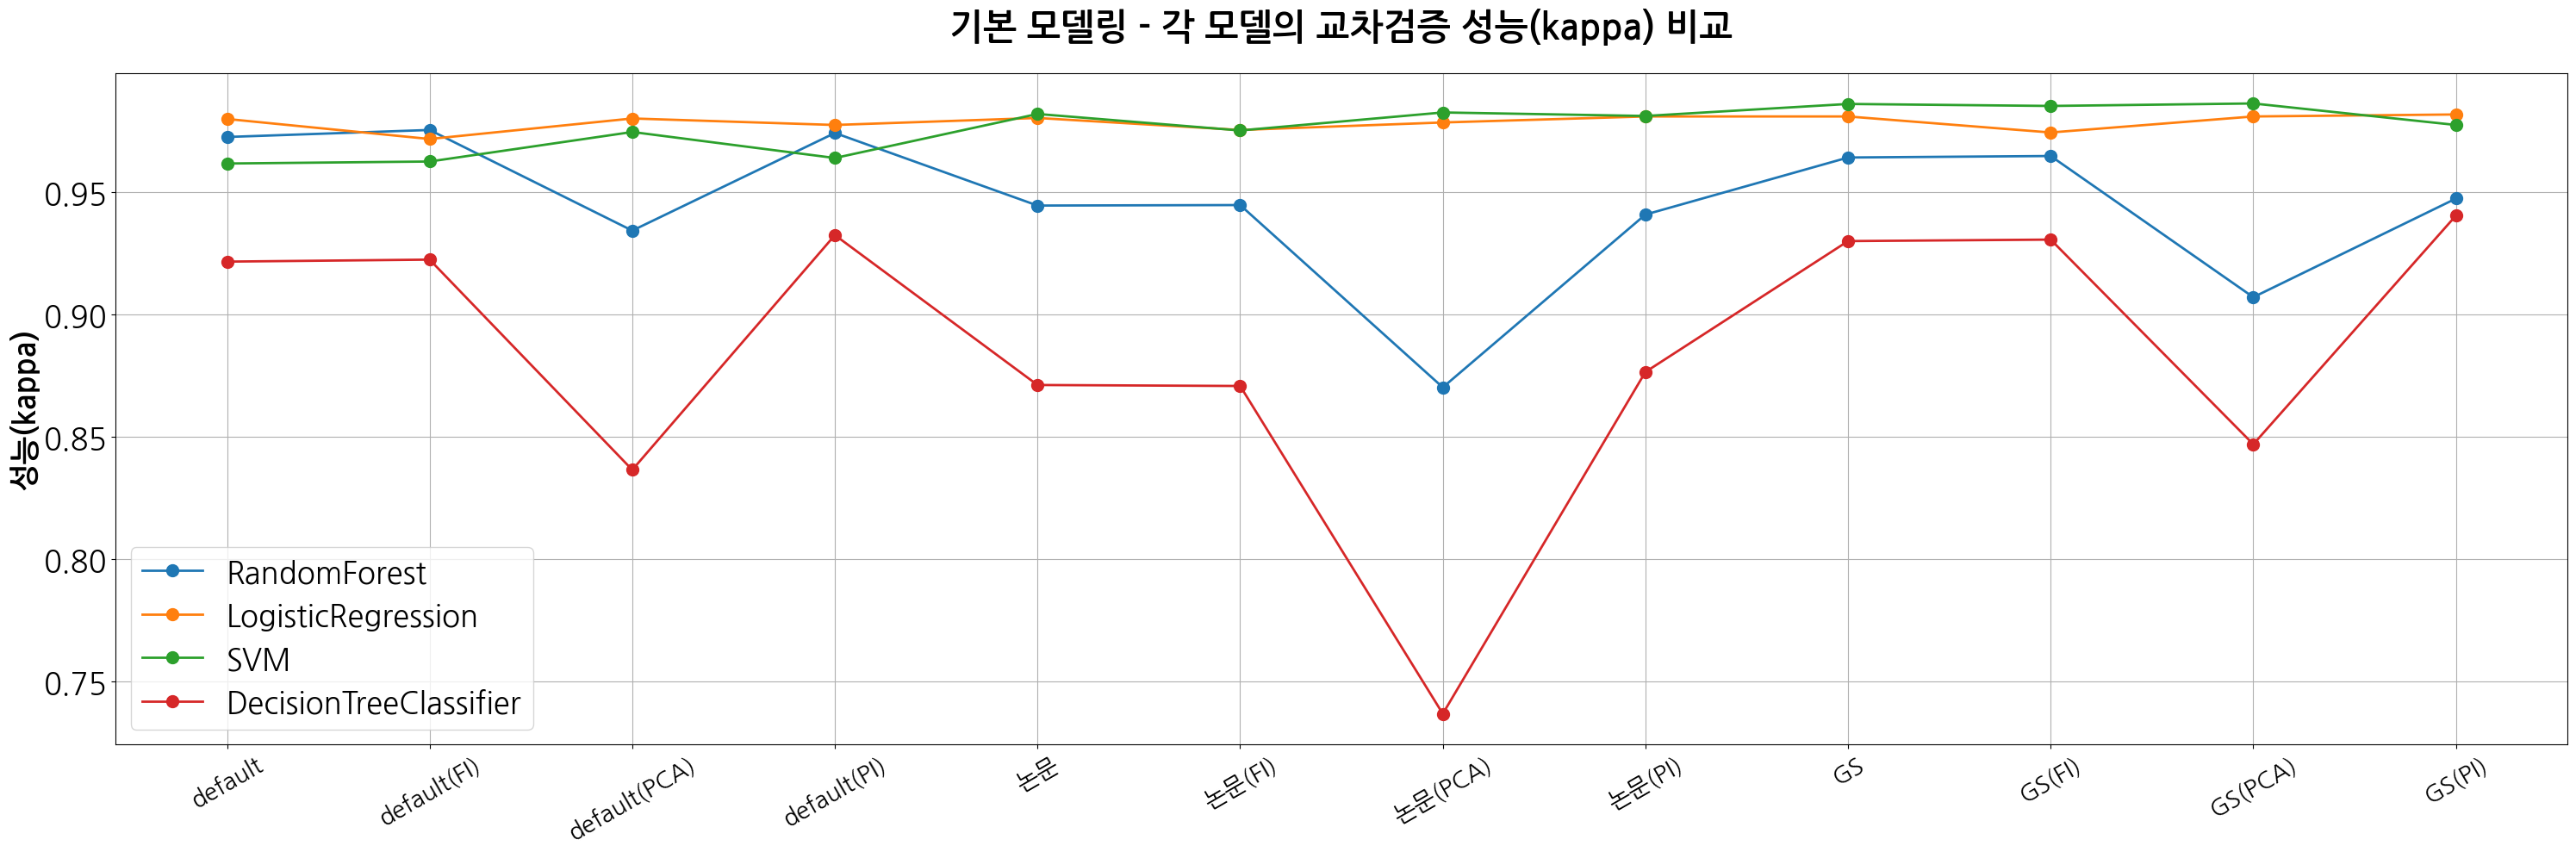

In [72]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']


rf_cv = df.loc['RandomForest', [
    'default_kappa(교차검증)', 'default_kappa(fi_교차검증)', 'default_kappa(pca_교차검증)', 'default_kappa(pi_교차검증)',
    '논문_kappa(교차검증)', '논문_kappa(fi_교차검증)', '논문_kappa(pca_교차검증)', '논문_kappa(pi_교차검증)',
    'gs_kappa(교차검증)', 'gs_kappa(fi_교차검증)', 'gs_kappa(pca_교차검증)', 'gs_kappa(pi_교차검증)'
]]

lr_cv = df.loc['LogisticRegression', [
    'default_kappa(교차검증)', 'default_kappa(fi_교차검증)', 'default_kappa(pca_교차검증)', 'default_kappa(pi_교차검증)',
    '논문_kappa(교차검증)', '논문_kappa(fi_교차검증)', '논문_kappa(pca_교차검증)', '논문_kappa(pi_교차검증)',
    'gs_kappa(교차검증)', 'gs_kappa(fi_교차검증)', 'gs_kappa(pca_교차검증)', 'gs_kappa(pi_교차검증)'
]]

svm_cv = df.loc['SVM', [
    'default_kappa(교차검증)', 'default_kappa(fi_교차검증)', 'default_kappa(pca_교차검증)', 'default_kappa(pi_교차검증)',
    '논문_kappa(교차검증)', '논문_kappa(fi_교차검증)', '논문_kappa(pca_교차검증)', '논문_kappa(pi_교차검증)',
    'gs_kappa(교차검증)', 'gs_kappa(fi_교차검증)', 'gs_kappa(pca_교차검증)', 'gs_kappa(pi_교차검증)'
]]

dt_cv = df.loc['DecisionTreeClassifier', [
    'default_kappa(교차검증)', 'default_kappa(fi_교차검증)', 'default_kappa(pca_교차검증)', 'default_kappa(pi_교차검증)',
    '논문_kappa(교차검증)', '논문_kappa(fi_교차검증)', '논문_kappa(pca_교차검증)', '논문_kappa(pi_교차검증)',
    'gs_kappa(교차검증)', 'gs_kappa(fi_교차검증)', 'gs_kappa(pca_교차검증)', 'gs_kappa(pi_교차검증)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, rf_cv.values, marker='o', markersize=10, linewidth=2, label='RandomForest')
plt.plot(x_labels, lr_cv.values, marker='o', markersize=10, linewidth=2, label='LogisticRegression')
plt.plot(x_labels, svm_cv.values, marker='o', markersize=10, linewidth=2, label='SVM')
plt.plot(x_labels, dt_cv.values, marker='o', markersize=10, linewidth=2, label='DecisionTreeClassifier')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(kappa)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - 각 모델의 교차검증 성능(kappa) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()

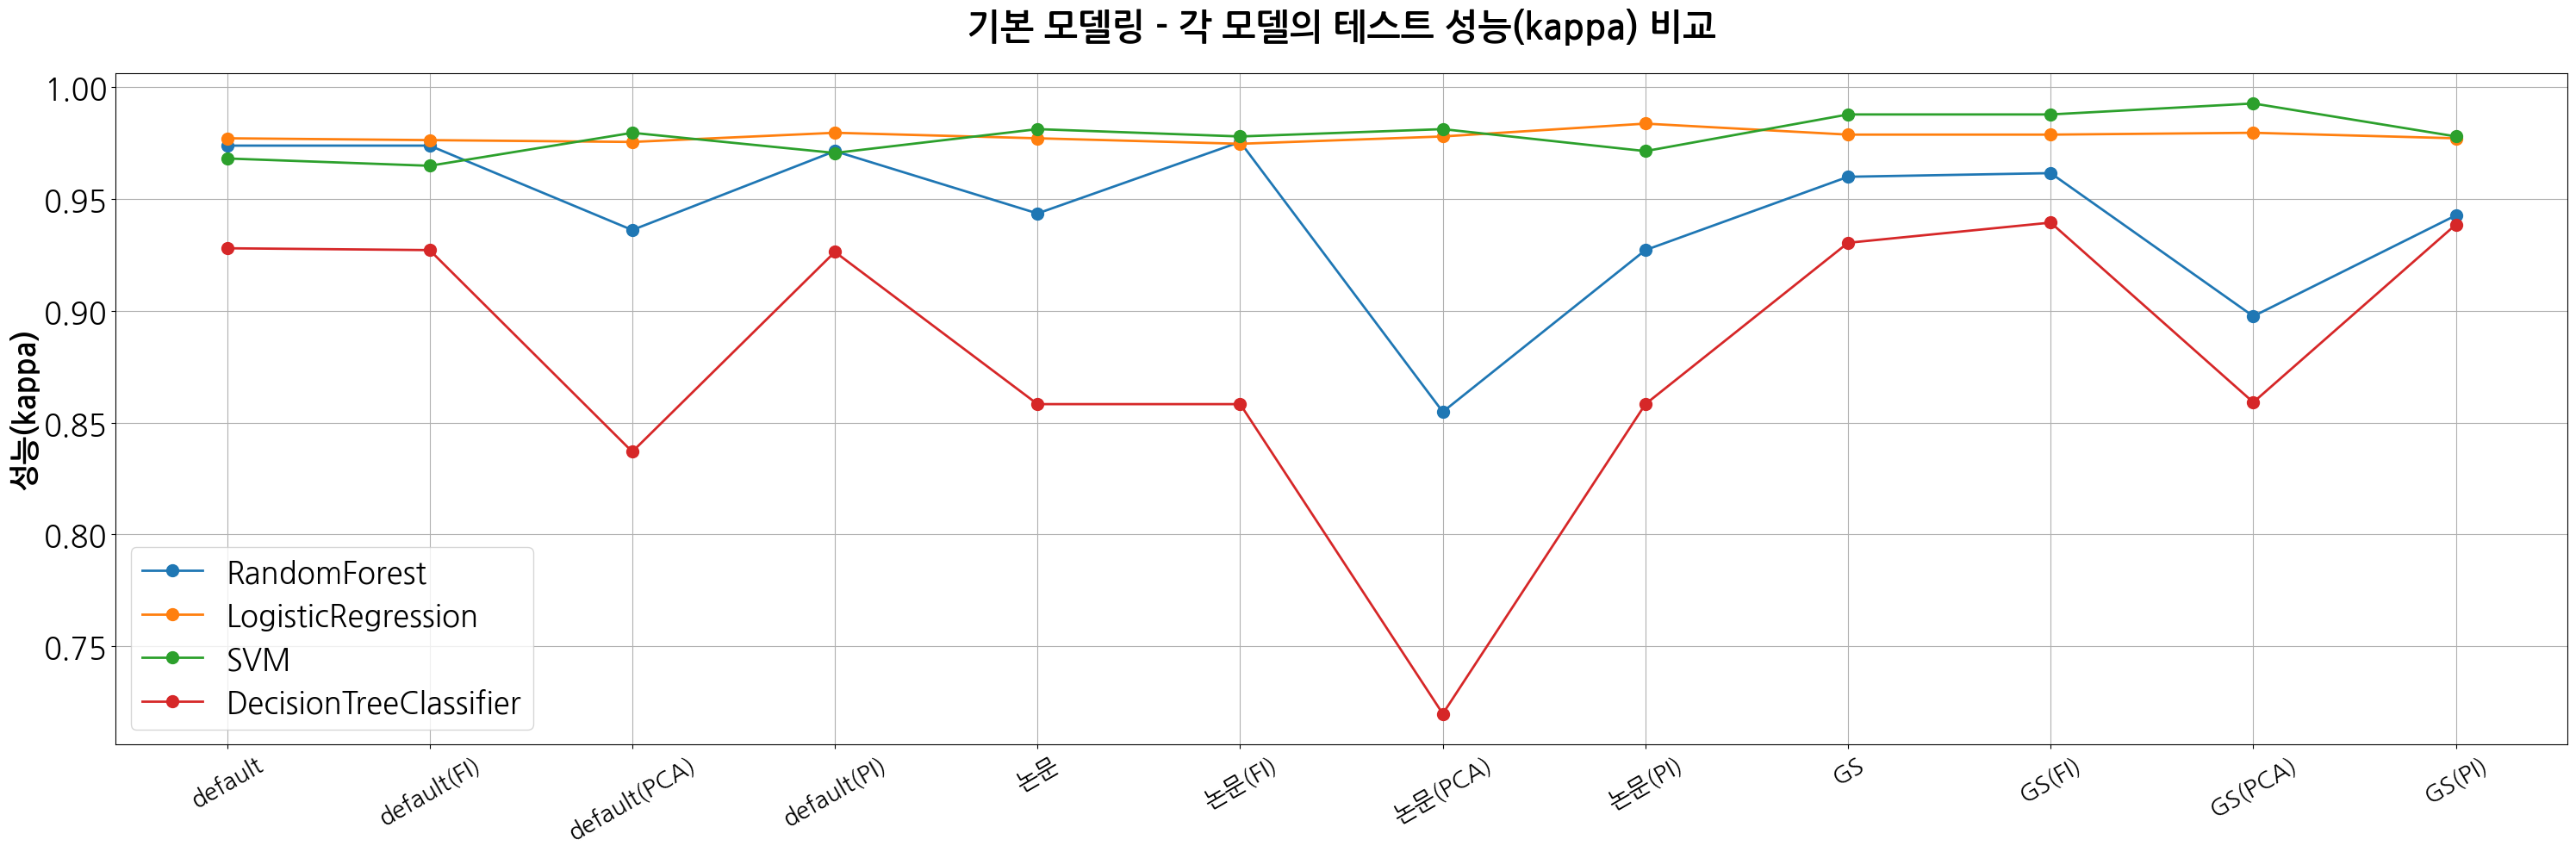

In [73]:
# x축 라벨
x_labels = ['default', 'default(FI)', 'default(PCA)', 'default(PI)',
            '논문', '논문(FI)', '논문(PCA)', '논문(PI)',
            'GS', 'GS(FI)', 'GS(PCA)', 'GS(PI)']

# RandomForest 테스트 및 교차검증 정확도 추출
rf_test = df.loc['RandomForest', [
    'default_kappa(테스트)', 'default_kappa(fi_테스트)', 'default_kappa(pca_테스트)', 'default_kappa(pi_테스트)',
    '논문_kappa(테스트)', '논문_kappa(fi_테스트)', '논문_kappa(pca_테스트)', '논문_kappa(pi_테스트)',
    'gs_kappa(테스트)', 'gs_kappa(fi_테스트)', 'gs_kappa(pca_테스트)', 'gs_kappa(pi_테스트)'
]]

lr_test = df.loc['LogisticRegression', [
    'default_kappa(테스트)', 'default_kappa(fi_테스트)', 'default_kappa(pca_테스트)', 'default_kappa(pi_테스트)',
    '논문_kappa(테스트)', '논문_kappa(fi_테스트)', '논문_kappa(pca_테스트)', '논문_kappa(pi_테스트)',
    'gs_kappa(테스트)', 'gs_kappa(fi_테스트)', 'gs_kappa(pca_테스트)', 'gs_kappa(pi_테스트)'
]]

svm_test = df.loc['SVM', [
    'default_kappa(테스트)', 'default_kappa(fi_테스트)', 'default_kappa(pca_테스트)', 'default_kappa(pi_테스트)',
    '논문_kappa(테스트)', '논문_kappa(fi_테스트)', '논문_kappa(pca_테스트)', '논문_kappa(pi_테스트)',
    'gs_kappa(테스트)', 'gs_kappa(fi_테스트)', 'gs_kappa(pca_테스트)', 'gs_kappa(pi_테스트)'
]]

dt_test = df.loc['DecisionTreeClassifier', [
    'default_kappa(테스트)', 'default_kappa(fi_테스트)', 'default_kappa(pca_테스트)', 'default_kappa(pi_테스트)',
    '논문_kappa(테스트)', '논문_kappa(fi_테스트)', '논문_kappa(pca_테스트)', '논문_kappa(pi_테스트)',
    'gs_kappa(테스트)', 'gs_kappa(fi_테스트)', 'gs_kappa(pca_테스트)', 'gs_kappa(pi_테스트)'
]]

# 그래프 그리기
plt.figure(figsize=(30, 10))
plt.plot(x_labels, rf_test.values, marker='o', markersize=10, linewidth=2, label='RandomForest')
plt.plot(x_labels, lr_test.values, marker='o', markersize=10, linewidth=2, label='LogisticRegression')
plt.plot(x_labels, svm_test.values, marker='o', markersize=10, linewidth=2, label='SVM')
plt.plot(x_labels, dt_test.values, marker='o', markersize=10, linewidth=2, label='DecisionTreeClassifier')

# # 각 지점에 정확도 주석 달기 (겹치지 않게 위/아래로)
# for i, (test_val, cv_val) in enumerate(zip(rf_test.values, rf_cv.values)):
#     plt.text(i, test_val + 0.005, f"{test_val:.4f}", ha='center', fontsize=20, color='blue')
#     plt.text(i, cv_val - 0.005, f"{cv_val:.4f}", ha='center', fontsize=20, color='red')

# 축, 제목, 범례 설정
plt.xticks(rotation=30, fontsize=20)
plt.yticks(fontsize=25)
plt.ylabel("성능(kappa)", fontsize=25, fontweight='bold')
plt.title("기본 모델링 - 각 모델의 테스트 성능(kappa) 비교", fontsize=30, fontweight='bold', pad=30)
plt.legend(fontsize=25)
plt.grid(True)
plt.tight_layout()
plt.show()